# Praktikum Data Mining: Klasifikasi dengan Decision Tree
Nama: Auditya Merosya Putri 
NIM: 24343001


## 3.1 Persiapan Lingkungan

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## 3.2 Load dan Eksplorasi Dataset Play Tennis

In [41]:
df = pd.read_csv('play_tennis.csv')
print(df.head())

  Day   Outlook Temperature Humidity    Wind PlayTennis
0  D1     Sunny         Hot     High    Weak         No
1  D2     Sunny         Hot     High  Strong         No
2  D3  Overcast         Hot     High    Weak        Yes
3  D4      Rain        Mild     High    Weak        Yes
4  D5      Rain        Cool   Normal    Weak        Yes


In [42]:
print(df['PlayTennis'].value_counts())

PlayTennis
Yes    9
No     5
Name: count, dtype: int64


## 3.3 Encoding Fitur Kategorikal

In [43]:
fitur = ['Outlook', 'Temperature', 'Humidity', 'Wind']
X = df[fitur].copy()
y = df['PlayTennis'].copy()

encoders = {}
X_enc = X.copy()
for col in fitur:
    le = LabelEncoder()
    X_enc[col] = le.fit_transform(X[col])
    encoders[col] = le
    print(f'{col}: { {str(k): int(v) for k, v in zip(le.classes_, le.transform(le.classes_))} }')

y_le = LabelEncoder()
y_enc = y_le.fit_transform(y)

Outlook: {'Overcast': 0, 'Rain': 1, 'Sunny': 2}
Temperature: {'Cool': 0, 'Hot': 1, 'Mild': 2}
Humidity: {'High': 0, 'Normal': 1}
Wind: {'Strong': 0, 'Weak': 1}


## 3.4 Membangun Model Decision Tree (criterion = entropy)

In [44]:
clf = DecisionTreeClassifier(criterion='entropy', random_state=42)
clf.fit(X_enc, y_enc)
print(export_text(clf, feature_names=fitur))

|--- Outlook <= 0.50
|   |--- class: 1
|--- Outlook >  0.50
|   |--- Humidity <= 0.50
|   |   |--- Outlook <= 1.50
|   |   |   |--- Wind <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Wind >  0.50
|   |   |   |   |--- class: 1
|   |   |--- Outlook >  1.50
|   |   |   |--- class: 0
|   |--- Humidity >  0.50
|   |   |--- Wind <= 0.50
|   |   |   |--- Temperature <= 1.00
|   |   |   |   |--- class: 0
|   |   |   |--- Temperature >  1.00
|   |   |   |   |--- class: 1
|   |   |--- Wind >  0.50
|   |   |   |--- class: 1



## 3.5 Visualisasi Pohon Keputusan

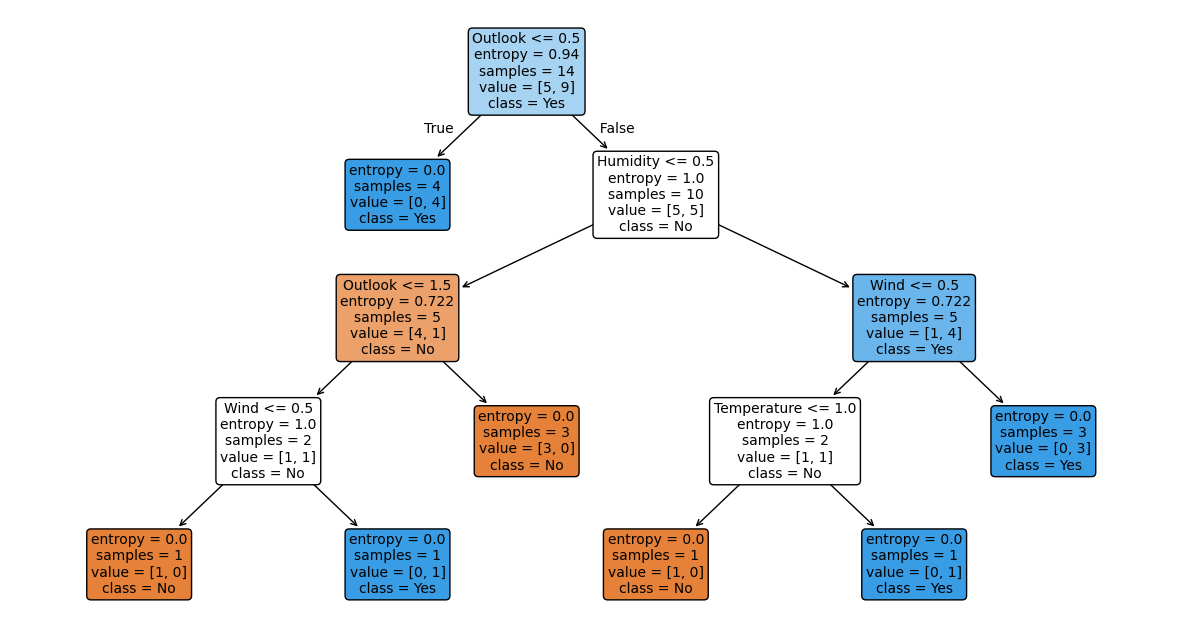

In [45]:
plt.figure(figsize=(15, 8))
plot_tree(clf, feature_names=fitur, class_names=y_le.classes_,
          filled=True, rounded=True, fontsize=10, impurity=True)
plt.savefig('tree_play_tennis.png', dpi=180, bbox_inches='tight')
plt.show()

## 3.6 Prediksi Data Baru

In [46]:
data_baru = pd.DataFrame([{
    'Outlook': 'Sunny', 'Temperature': 'Cool',
    'Humidity': 'High', 'Wind': 'Strong'
}])
data_baru_enc = data_baru.copy()
for col in fitur:
    data_baru_enc[col] = encoders[col].transform(data_baru[col])

pred = clf.predict(data_baru_enc)
print('Prediksi:', y_le.inverse_transform(pred)[0])

Prediksi: No


## 3.7 Evaluasi Model dengan Dataset Iris

In [47]:
from sklearn.datasets import load_iris

iris = load_iris()
Xi = pd.DataFrame(iris.data, columns=iris.feature_names)
yi = iris.target

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    Xi, yi, test_size=0.3, random_state=42, stratify=yi)
print(f'Data latih: {len(Xi_train)} | Data uji: {len(Xi_test)}')

Data latih: 105 | Data uji: 45


In [48]:
clf_iris = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
clf_iris.fit(Xi_train, yi_train)
y_pred = clf_iris.predict(Xi_test)

print('Akurasi:', accuracy_score(yi_test, y_pred))
print(classification_report(yi_test, y_pred, target_names=iris.target_names, digits=3))

Akurasi: 0.9333333333333333
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      1.000     0.800     0.889        15
   virginica      0.833     1.000     0.909        15

    accuracy                          0.933        45
   macro avg      0.944     0.933     0.933        45
weighted avg      0.944     0.933     0.933        45



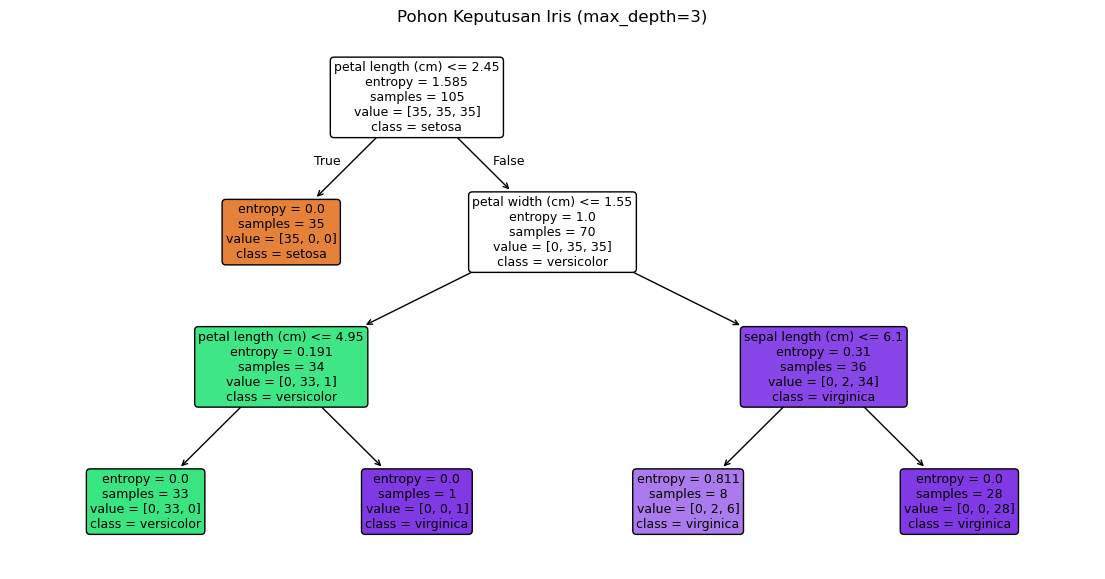

In [49]:
plt.figure(figsize=(14, 7))
plot_tree(clf_iris, feature_names=iris.feature_names, class_names=iris.target_names,
          filled=True, rounded=True, fontsize=9, impurity=True)
plt.title('Pohon Keputusan Iris (max_depth=3)')
plt.savefig('tree_iris.png', dpi=180, bbox_inches='tight')
plt.show()

[[15  0  0]
 [ 0 12  3]
 [ 0  0 15]]


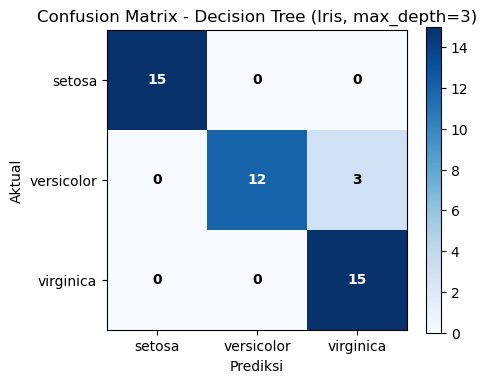

In [50]:
cm = confusion_matrix(yi_test, y_pred)
print(cm)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(3)); ax.set_yticks(range(3))
ax.set_xticklabels(iris.target_names); ax.set_yticklabels(iris.target_names)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
ax.set_title('Confusion Matrix - Decision Tree (Iris, max_depth=3)')
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black', fontweight='bold')
fig.colorbar(im)
plt.tight_layout()
plt.savefig('confusion_matrix_iris.png', dpi=180)
plt.show()

## 3.8 Eksperimen: Pengaruh max_depth terhadap Akurasi

In [51]:
depths = [1, 2, 3, 4, 5, None]
akurasi_list = []
for depth in depths:
    c = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=42)
    c.fit(Xi_train, yi_train)
    acc = accuracy_score(yi_test, c.predict(Xi_test))
    akurasi_list.append(acc)
    print(f'max_depth={depth}: akurasi = {acc:.4f}')

max_depth=1: akurasi = 0.6667
max_depth=2: akurasi = 0.8889
max_depth=3: akurasi = 0.9333
max_depth=4: akurasi = 0.8889
max_depth=5: akurasi = 0.8889
max_depth=None: akurasi = 0.8889


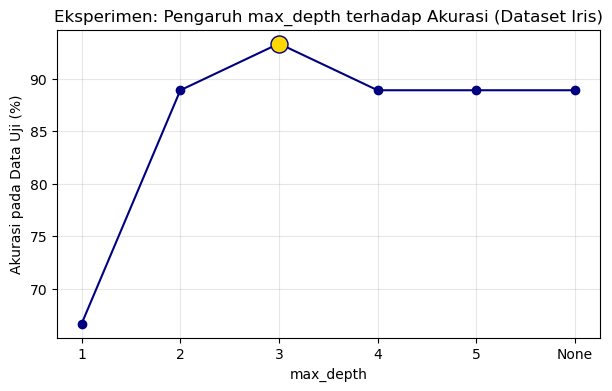

In [52]:
labels = [str(d) for d in depths]
best = int(np.argmax(akurasi_list))
plt.figure(figsize=(7, 4))
plt.plot(labels, np.array(akurasi_list) * 100, marker='o', color='navy')
plt.scatter(labels[best], akurasi_list[best] * 100, s=150, color='gold', edgecolor='navy', zorder=3)
plt.xlabel('max_depth'); plt.ylabel('Akurasi pada Data Uji (%)')
plt.title('Eksperimen: Pengaruh max_depth terhadap Akurasi (Dataset Iris)')
plt.grid(alpha=0.3)
plt.savefig('eksperimen_max_depth.png', dpi=180, bbox_inches='tight')
plt.show()

---
# TUGAS 1: Modifikasi Data Play Tennis
Tambah 3 baris data baru (D15-D17), lalu ulangi langkah 4.3-4.6 dan bandingkan dengan pohon sebelumnya.

### 1.Tambah 3 baris data baru

In [53]:
baris_baru = pd.DataFrame([
    {'Day': 'D15', 'Outlook': 'Sunny', 'Temperature': 'Cool', 'Humidity': 'Normal', 'Wind': 'Weak',   'PlayTennis': 'Yes'},
    {'Day': 'D16', 'Outlook': 'Sunny', 'Temperature': 'Mild', 'Humidity': 'Normal', 'Wind': 'Weak',   'PlayTennis': 'Yes'},
    {'Day': 'D17', 'Outlook': 'Rain',  'Temperature': 'Cool', 'Humidity': 'Normal', 'Wind': 'Weak',   'PlayTennis': 'Yes'},
])
df2 = pd.concat([df, baris_baru], ignore_index=True)
df2.to_csv('play_tennis_modifikasi.csv', index=False)
print(df2)
print()
print(df2['PlayTennis'].value_counts())

    Day   Outlook Temperature Humidity    Wind PlayTennis
0    D1     Sunny         Hot     High    Weak         No
1    D2     Sunny         Hot     High  Strong         No
2    D3  Overcast         Hot     High    Weak        Yes
3    D4      Rain        Mild     High    Weak        Yes
4    D5      Rain        Cool   Normal    Weak        Yes
5    D6      Rain        Cool   Normal  Strong         No
6    D7  Overcast        Cool   Normal  Strong        Yes
7    D8     Sunny        Mild     High    Weak         No
8    D9     Sunny        Cool   Normal    Weak        Yes
9   D10      Rain        Mild   Normal    Weak        Yes
10  D11     Sunny        Mild   Normal  Strong        Yes
11  D12  Overcast        Mild     High  Strong        Yes
12  D13  Overcast         Hot   Normal    Weak        Yes
13  D14      Rain        Mild     High  Strong         No
14  D15     Sunny        Cool   Normal    Weak        Yes
15  D16     Sunny        Mild   Normal    Weak        Yes
16  D17      R

### 2. Encoding (ulang langkah 3.3)

In [54]:
X2 = df2[fitur].copy()
y2 = df2['PlayTennis'].copy()

encoders2 = {}
X2_enc = X2.copy()
for col in fitur:
    le = LabelEncoder()
    X2_enc[col] = le.fit_transform(X2[col])
    encoders2[col] = le
    print(f'{col}: { {str(k): int(v) for k, v in zip(le.classes_, le.transform(le.classes_))} }')

y2_le = LabelEncoder()
y2_enc = y2_le.fit_transform(y2)

Outlook: {'Overcast': 0, 'Rain': 1, 'Sunny': 2}
Temperature: {'Cool': 0, 'Hot': 1, 'Mild': 2}
Humidity: {'High': 0, 'Normal': 1}
Wind: {'Strong': 0, 'Weak': 1}


### 3. Bangun model baru (ulang langkah 3.4)

In [55]:
clf2 = DecisionTreeClassifier(criterion='entropy', random_state=42)
clf2.fit(X2_enc, y2_enc)
print(export_text(clf2, feature_names=fitur))

|--- Humidity <= 0.50
|   |--- Outlook <= 1.50
|   |   |--- Wind <= 0.50
|   |   |   |--- Outlook <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Outlook >  0.50
|   |   |   |   |--- class: 0
|   |   |--- Wind >  0.50
|   |   |   |--- class: 1
|   |--- Outlook >  1.50
|   |   |--- class: 0
|--- Humidity >  0.50
|   |--- Wind <= 0.50
|   |   |--- Outlook <= 0.50
|   |   |   |--- class: 1
|   |   |--- Outlook >  0.50
|   |   |   |--- Temperature <= 1.00
|   |   |   |   |--- class: 0
|   |   |   |--- Temperature >  1.00
|   |   |   |   |--- class: 1
|   |--- Wind >  0.50
|   |   |--- class: 1



### 4. Visualisasi pohon baru (ulang langkah 3.5)

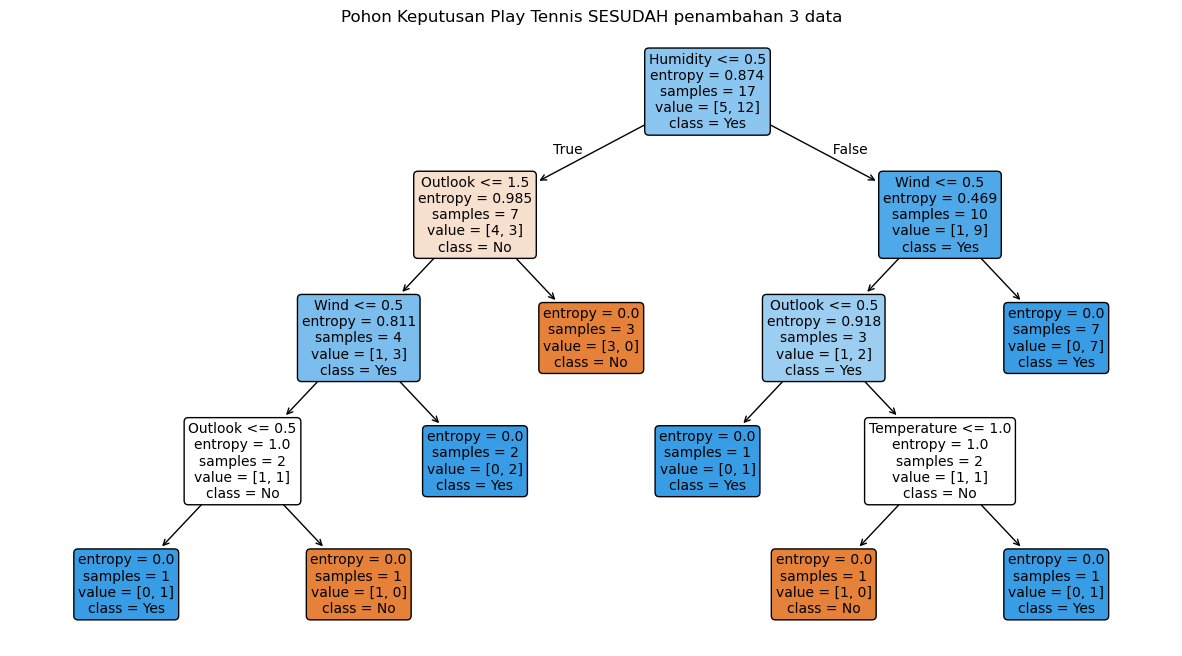

In [56]:
plt.figure(figsize=(15, 8))
plot_tree(clf2, feature_names=fitur, class_names=y2_le.classes_,
          filled=True, rounded=True, fontsize=10, impurity=True)
plt.title('Pohon Keputusan Play Tennis SESUDAH penambahan 3 data')
plt.savefig('tree_play_tennis_modifikasi.png', dpi=180, bbox_inches='tight')
plt.show()

### 5. Prediksi data baru (ulang langkah 3.6)

In [57]:
data_baru2_enc = data_baru.copy()
for col in fitur:
    data_baru2_enc[col] = encoders2[col].transform(data_baru[col])

pred2 = clf2.predict(data_baru2_enc)
print('Prediksi SEBELUM penambahan data:', y_le.inverse_transform(pred)[0])
print('Prediksi SESUDAH penambahan data:', y2_le.inverse_transform(pred2)[0])

Prediksi SEBELUM penambahan data: No
Prediksi SESUDAH penambahan data: No


### 6. Perbandingan: apakah root node berubah? (hitung Information Gain)

In [58]:
def entropy(s):
    p = s.value_counts(normalize=True)
    return -(p * np.log2(p)).sum()

def information_gain(data, atribut, target='PlayTennis'):
    total = entropy(data[target])
    sisa = sum(len(g) / len(data) * entropy(g[target]) for _, g in data.groupby(atribut))
    return total - sisa

hasil = pd.DataFrame({
    'Gain SEBELUM (14 data)': {f: information_gain(df, f) for f in fitur},
    'Gain SESUDAH (17 data)': {f: information_gain(df2, f) for f in fitur},
}).round(3)
print(f"Entropy total sebelum: {entropy(df['PlayTennis']):.3f}")
print(f"Entropy total sesudah: {entropy(df2['PlayTennis']):.3f}\n")
print(hasil)

print('\nRoot node SEBELUM:', fitur[clf.tree_.feature[0]])
print('Root node SESUDAH:', fitur[clf2.tree_.feature[0]])

Entropy total sebelum: 0.940
Entropy total sesudah: 0.874

             Gain SEBELUM (14 data)  Gain SESUDAH (17 data)
Outlook                       0.247                   0.144
Temperature                   0.029                   0.054
Humidity                      0.152                   0.192
Wind                          0.048                   0.078

Root node SEBELUM: Outlook
Root node SESUDAH: Humidity


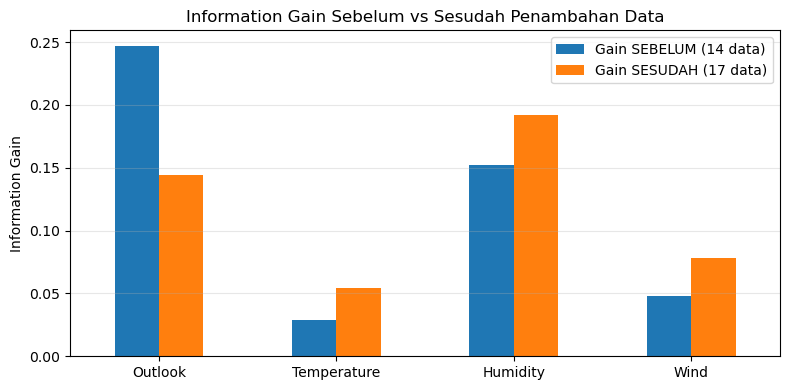

In [59]:
hasil.plot(kind='bar', figsize=(8, 4), rot=0)
plt.ylabel('Information Gain'); plt.title('Information Gain Sebelum vs Sesudah Penambahan Data')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.datasets import load_iris, load_breast_cancer

# Data Iris dengan split yang sama seperti langkah 4.7
iris = load_iris()
Xi = pd.DataFrame(iris.data, columns=iris.feature_names)
yi = iris.target
Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    Xi, yi, test_size=0.3, random_state=42, stratify=yi)
print('Data latih:', len(Xi_train), '| Data uji:', len(Xi_test))

Data latih: 105 | Data uji: 45


---
# TUGAS 2: Eksperimen Kriteria Split (entropy vs gini)

### 1. Latih dua model (max_depth=3, split sama)

In [61]:
clf_ent = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42).fit(Xi_train, yi_train)
clf_gini = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42).fit(Xi_train, yi_train)

for nama, m in [('entropy', clf_ent), ('gini', clf_gini)]:
    yp = m.predict(Xi_test)
    print(f'===== criterion = {nama} =====')
    print('Akurasi:', accuracy_score(yi_test, yp))
    print(classification_report(yi_test, yp, target_names=iris.target_names, digits=3))
    print('Confusion matrix:\n', confusion_matrix(yi_test, yp), '\n')

===== criterion = entropy =====
Akurasi: 0.9333333333333333
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      1.000     0.800     0.889        15
   virginica      0.833     1.000     0.909        15

    accuracy                          0.933        45
   macro avg      0.944     0.933     0.933        45
weighted avg      0.944     0.933     0.933        45

Confusion matrix:
 [[15  0  0]
 [ 0 12  3]
 [ 0  0 15]] 

===== criterion = gini =====
Akurasi: 0.9777777777777777
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      1.000     0.933     0.966        15
   virginica      0.938     1.000     0.968        15

    accuracy                          0.978        45
   macro avg      0.979     0.978     0.978        45
weighted avg      0.979     0.978     0.978        45

Confusion matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  0 15]] 



### 2. Bandingkan struktur pohon

In [62]:
print('===== ENTROPY =====')
print(export_text(clf_ent, feature_names=list(iris.feature_names)))
print('===== GINI =====')
print(export_text(clf_gini, feature_names=list(iris.feature_names)))

===== ENTROPY =====
|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.55
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.55
|   |   |--- sepal length (cm) <= 6.10
|   |   |   |--- class: 2
|   |   |--- sepal length (cm) >  6.10
|   |   |   |--- class: 2

===== GINI =====
|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.55
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.55
|   |   |--- petal width (cm) <= 1.70
|   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.70
|   |   |   |--- class: 2



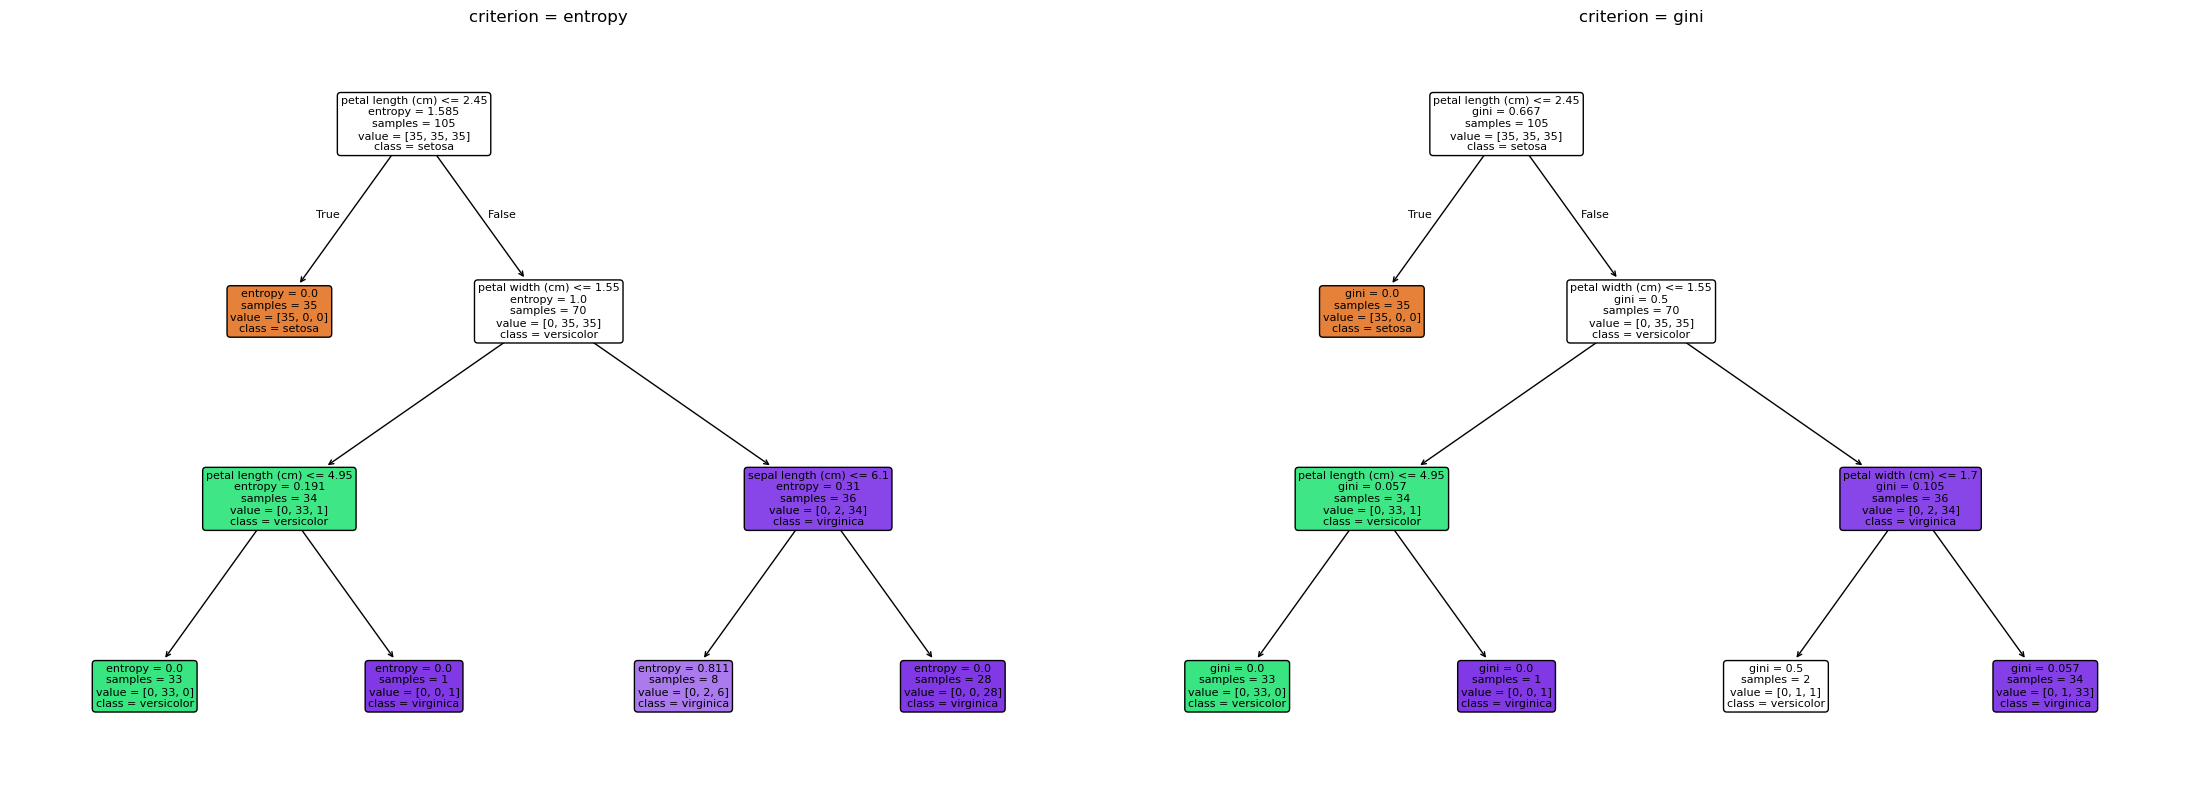

Jumlah node  entropy: 9 | gini: 9
Jumlah daun  entropy: 5 | gini: 5
Kedalaman    entropy: 3 | gini: 3


In [63]:
fig, axes = plt.subplots(1, 2, figsize=(22, 8))
for ax, m, judul in zip(axes, [clf_ent, clf_gini], ['criterion = entropy', 'criterion = gini']):
    plot_tree(m, feature_names=iris.feature_names, class_names=iris.target_names,
              filled=True, rounded=True, fontsize=8, ax=ax)
    ax.set_title(judul)
plt.tight_layout()
plt.savefig('tugas2_pohon_entropy_vs_gini.png', dpi=150, bbox_inches='tight')
plt.show()

print('Jumlah node  entropy:', clf_ent.tree_.node_count, '| gini:', clf_gini.tree_.node_count)
print('Jumlah daun  entropy:', clf_ent.get_n_leaves(), '| gini:', clf_gini.get_n_leaves())
print('Kedalaman    entropy:', clf_ent.get_depth(), '| gini:', clf_gini.get_depth())

### 3. Feature importance

                   entropy    gini
sepal length (cm)   0.0291  0.0000
sepal width (cm)    0.0000  0.0000
petal length (cm)   0.6436  0.5509
petal width (cm)    0.3273  0.4491


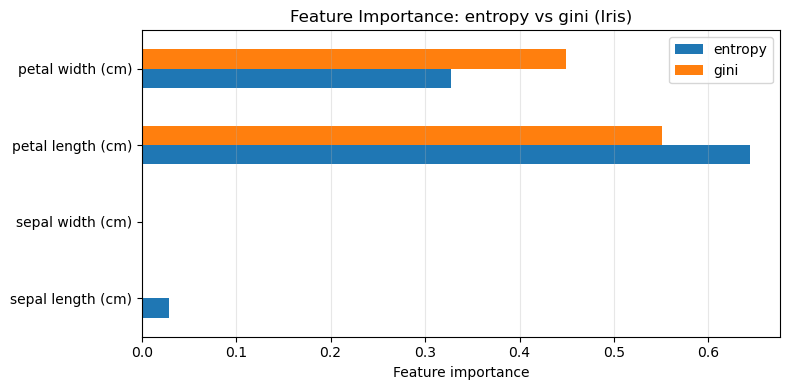

In [64]:
fi = pd.DataFrame({
    'entropy': clf_ent.feature_importances_,
    'gini': clf_gini.feature_importances_
}, index=iris.feature_names).round(4)
print(fi)

fi.plot(kind='barh', figsize=(8, 4))
plt.xlabel('Feature importance'); plt.title('Feature Importance: entropy vs gini (Iris)')
plt.grid(axis='x', alpha=0.3); plt.tight_layout()
plt.savefig('tugas2_feature_importance.png', dpi=150)
plt.show()

### 4. Apakah perbedaannya signifikan? (uji lebih kuat: berbagai depth dan 5-fold CV)

In [65]:
baris = []
for d in [1, 2, 3, 4, 5, None]:
    row = {'max_depth': str(d)}
    for crit in ['entropy', 'gini']:
        m = DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=42).fit(Xi_train, yi_train)
        row[f'test_{crit}'] = round(accuracy_score(yi_test, m.predict(Xi_test)), 4)
        cv = cross_val_score(DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=42), Xi, yi, cv=5)
        row[f'cv_{crit}'] = f'{cv.mean():.4f} (+/- {cv.std():.3f})'
    baris.append(row)
print(pd.DataFrame(baris).to_string(index=False))

max_depth  test_entropy         cv_entropy  test_gini            cv_gini
        1        0.6667 0.6667 (+/- 0.000)     0.6667 0.6667 (+/- 0.000)
        2        0.8889 0.9333 (+/- 0.047)     0.8889 0.9333 (+/- 0.047)
        3        0.9333 0.9600 (+/- 0.025)     0.9778 0.9733 (+/- 0.025)
        4        0.8889 0.9533 (+/- 0.034)     0.8889 0.9533 (+/- 0.034)
        5        0.8889 0.9533 (+/- 0.034)     0.9333 0.9533 (+/- 0.034)
     None        0.8889 0.9533 (+/- 0.034)     0.9333 0.9533 (+/- 0.034)


---
# TUGAS 3: Dataset Baru (Breast Cancer Wisconsin)
Dataset diagnosis kanker payudara: **569 baris**, 30 fitur numerik, target kategorikal 2 kelas (malignant / benign). Dataset tersedia di scikit-learn (sumber asli: UCI Machine Learning Repository), jadi memenuhi syarat minimal 50 baris dan target kategorikal.

### Load dan eksplorasi

In [66]:
bc = load_breast_cancer()
df3 = pd.DataFrame(bc.data, columns=bc.feature_names)
df3['diagnosis'] = [bc.target_names[i] for i in bc.target]   # target dalam bentuk teks
df3.to_csv('breast_cancer.csv', index=False)

print('Ukuran data:', df3.shape)
print(df3.head())
print()
print(df3['diagnosis'].value_counts())
print('\nMissing value per kolom (total):', df3.isnull().sum().sum())

Ukuran data: (569, 31)
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst

### 1. Encoding
Semua fitur sudah numerik sehingga tidak perlu di-encode. Hanya target (teks) yang di-encode dengan `LabelEncoder`.

In [67]:
X3 = df3.drop(columns='diagnosis')
y3_le = LabelEncoder()
y3 = y3_le.fit_transform(df3['diagnosis'])
print('Encoding target:', {str(k): int(v) for k, v in zip(y3_le.classes_, y3_le.transform(y3_le.classes_))})

Encoding target: {'benign': 0, 'malignant': 1}


### 2. Split data latih/uji

In [68]:
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.3, random_state=42, stratify=y3)
print(f'Data latih: {len(X3_train)} | Data uji: {len(X3_test)}')

Data latih: 398 | Data uji: 171


### 3. Bangun model

In [69]:
clf3 = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
clf3.fit(X3_train, y3_train)
print(export_text(clf3, feature_names=list(X3.columns)))

|--- worst perimeter <= 112.80
|   |--- worst concave points <= 0.18
|   |   |--- mean texture <= 21.32
|   |   |   |--- class: 0
|   |   |--- mean texture >  21.32
|   |   |   |--- class: 0
|   |--- worst concave points >  0.18
|   |   |--- class: 1
|--- worst perimeter >  112.80
|   |--- worst concave points <= 0.14
|   |   |--- mean texture <= 16.78
|   |   |   |--- class: 0
|   |   |--- mean texture >  16.78
|   |   |   |--- class: 1
|   |--- worst concave points >  0.14
|   |   |--- class: 1



### 4. Visualisasi

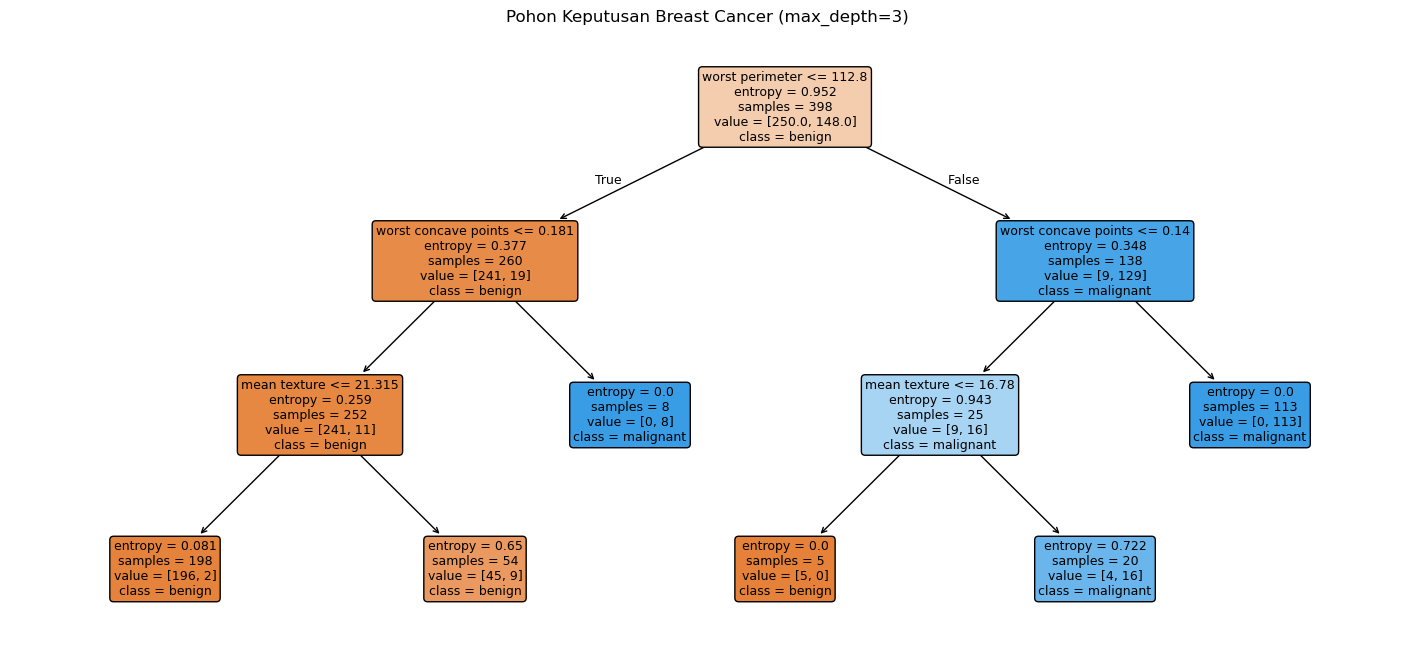

In [70]:
plt.figure(figsize=(18, 8))
plot_tree(clf3, feature_names=X3.columns, class_names=y3_le.classes_,
          filled=True, rounded=True, fontsize=9)
plt.title('Pohon Keputusan Breast Cancer (max_depth=3)')
plt.savefig('tugas3_pohon.png', dpi=150, bbox_inches='tight')
plt.show()

### 5. Evaluasi

Akurasi data uji : 0.9181
Akurasi data latih: 0.9623
              precision    recall  f1-score   support

      benign      0.884     1.000     0.939       107
   malignant      1.000     0.781     0.877        64

    accuracy                          0.918       171
   macro avg      0.942     0.891     0.908       171
weighted avg      0.928     0.918     0.916       171

Confusion matrix:
 [[107   0]
 [ 14  50]]


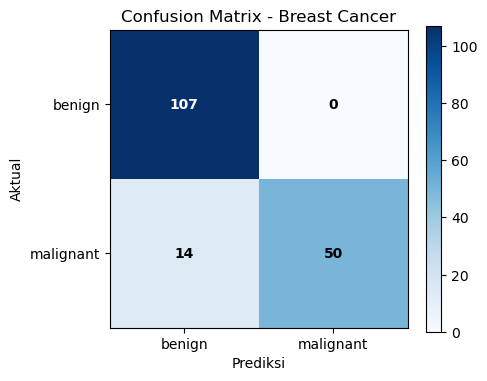


Fitur terpenting:
worst perimeter         0.7433
worst concave points    0.1830
mean texture            0.0738
dtype: float64


In [71]:
y3_pred = clf3.predict(X3_test)
print('Akurasi data uji :', round(accuracy_score(y3_test, y3_pred), 4))
print('Akurasi data latih:', round(accuracy_score(y3_train, clf3.predict(X3_train)), 4))
print(classification_report(y3_test, y3_pred, target_names=y3_le.classes_, digits=3))

cm3 = confusion_matrix(y3_test, y3_pred)
print('Confusion matrix:\n', cm3)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm3, cmap='Blues')
ax.set_xticks(range(2)); ax.set_yticks(range(2))
ax.set_xticklabels(y3_le.classes_); ax.set_yticklabels(y3_le.classes_)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
ax.set_title('Confusion Matrix - Breast Cancer')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm3[i, j], ha='center', va='center',
                color='white' if cm3[i, j] > cm3.max() / 2 else 'black', fontweight='bold')
fig.colorbar(im); plt.tight_layout()
plt.savefig('tugas3_confusion_matrix.png', dpi=150)
plt.show()

imp = pd.Series(clf3.feature_importances_, index=X3.columns).sort_values(ascending=False)
print('\nFitur terpenting:')
print(imp[imp > 0].round(4))

---
# TUGAS 4: Analisis Kritis

### 1. Hubungan kompleksitas model dengan overfitting dan underfitting
Bandingkan akurasi **data latih** dan **data uji** untuk setiap kedalaman pohon (Iris).

 max_depth  akurasi_latih  akurasi_uji  selisih
         1         0.6667       0.6667   0.0000
         2         0.9714       0.8889   0.0825
         3         0.9810       0.9333   0.0477
         4         0.9905       0.8889   0.1016
         5         0.9905       0.8889   0.1016
         6         1.0000       0.8889   0.1111
         7         1.0000       0.8889   0.1111
         8         1.0000       0.8889   0.1111
         9         1.0000       0.8889   0.1111
        10         1.0000       0.8889   0.1111


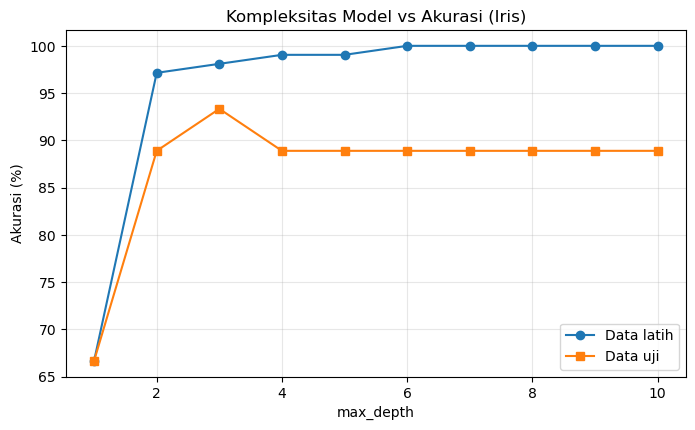

In [72]:
depths = list(range(1, 11))
tr, te = [], []
for d in depths:
    m = DecisionTreeClassifier(criterion='entropy', max_depth=d, random_state=42).fit(Xi_train, yi_train)
    tr.append(accuracy_score(yi_train, m.predict(Xi_train)))
    te.append(accuracy_score(yi_test, m.predict(Xi_test)))

hasil = pd.DataFrame({'max_depth': depths, 'akurasi_latih': np.round(tr, 4), 'akurasi_uji': np.round(te, 4)})
hasil['selisih'] = (hasil['akurasi_latih'] - hasil['akurasi_uji']).round(4)
print(hasil.to_string(index=False))

plt.figure(figsize=(8, 4.5))
plt.plot(depths, np.array(tr) * 100, marker='o', label='Data latih')
plt.plot(depths, np.array(te) * 100, marker='s', label='Data uji')
plt.xlabel('max_depth'); plt.ylabel('Akurasi (%)')
plt.title('Kompleksitas Model vs Akurasi (Iris)')
plt.legend(); plt.grid(alpha=0.3)
plt.savefig('tugas4_latih_vs_uji.png', dpi=150, bbox_inches='tight')
plt.show()

### 2. Menentukan max_depth optimal tanpa mengintip data uji: Cross-Validation dan GridSearchCV

max_depth= 1: CV akurasi = 0.6667 (+/- 0.0000)
max_depth= 2: CV akurasi = 0.9429 (+/- 0.0190)
max_depth= 3: CV akurasi = 0.9524 (+/- 0.0301)
max_depth= 4: CV akurasi = 0.9429 (+/- 0.0190)
max_depth= 5: CV akurasi = 0.9429 (+/- 0.0190)
max_depth= 6: CV akurasi = 0.9429 (+/- 0.0190)
max_depth= 7: CV akurasi = 0.9429 (+/- 0.0190)
max_depth= 8: CV akurasi = 0.9429 (+/- 0.0190)
max_depth= 9: CV akurasi = 0.9429 (+/- 0.0190)
max_depth=10: CV akurasi = 0.9429 (+/- 0.0190)


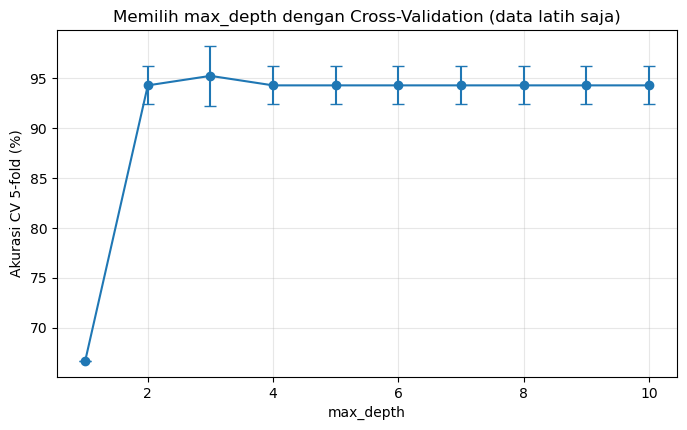

In [73]:
# (a) Cross-validation 5-fold HANYA pada data latih
cv_mean, cv_std = [], []
for d in depths:
    s = cross_val_score(DecisionTreeClassifier(criterion='entropy', max_depth=d, random_state=42),
                        Xi_train, yi_train, cv=5)
    cv_mean.append(s.mean()); cv_std.append(s.std())
    print(f'max_depth={d:>2}: CV akurasi = {s.mean():.4f} (+/- {s.std():.4f})')

plt.figure(figsize=(8, 4.5))
plt.errorbar(depths, np.array(cv_mean) * 100, yerr=np.array(cv_std) * 100, marker='o', capsize=4)
plt.xlabel('max_depth'); plt.ylabel('Akurasi CV 5-fold (%)')
plt.title('Memilih max_depth dengan Cross-Validation (data latih saja)')
plt.grid(alpha=0.3)
plt.savefig('tugas4_cv.png', dpi=150, bbox_inches='tight')
plt.show()

In [74]:
# (b) GridSearchCV: cari kombinasi parameter terbaik, hanya memakai data latih
param_grid = {
    'max_depth': [1, 2, 3, 4, 5, 6, None],
    'criterion': ['entropy', 'gini'],
    'min_samples_leaf': [1, 2, 5],
}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring='accuracy')
grid.fit(Xi_train, yi_train)

print('Parameter terbaik   :', grid.best_params_)
print('Akurasi CV terbaik  :', round(grid.best_score_, 4))

# Data uji baru dipakai SEKALI, setelah parameter ditentukan
best = grid.best_estimator_
print('Akurasi data uji (model terbaik):', round(accuracy_score(yi_test, best.predict(Xi_test)), 4))

top = pd.DataFrame(grid.cv_results_)[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']]
print('\n10 kombinasi teratas:')
print(top.sort_values('rank_test_score').head(10).to_string(index=False))

Parameter terbaik   : {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1}
Akurasi CV terbaik  : 0.9524
Akurasi data uji (model terbaik): 0.9333

10 kombinasi teratas:
                                                            params  mean_test_score  std_test_score  rank_test_score
   {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 2}         0.952381        0.030117                1
      {'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 2}         0.952381        0.030117                1
{'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 2}         0.952381        0.030117                1
      {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1}         0.952381        0.030117                1
   {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1}         0.952381        0.030117                1
   {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 2}         0.952381        0.030117                1
  